# Tapaaminen 8: Normaalijakauma ja kuvien käsittely

In [19]:
import numpy as np
import matplotlib.pyplot as plt
import scipy # install this
from scipy.stats import multivariate_normal

## About probability distributions

Probability distribution is a function that gives the probabilities of different outcomes of an experiment or observation. The probabilities (in discrete case) are between 0 and 1, and the sum of all outcomes is 1.

For a discrete case, a probability distribution could look like this:

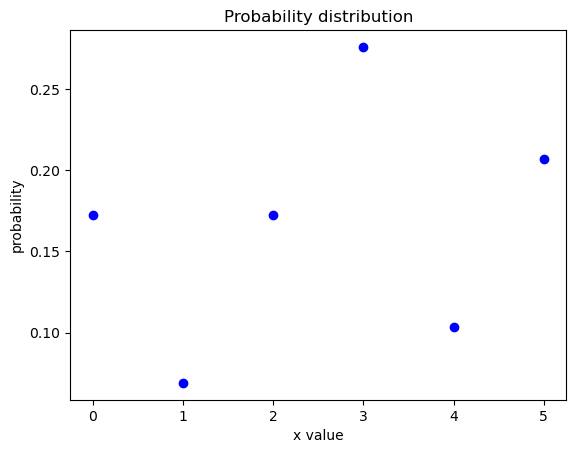

In [20]:
histdata = np.array([0,1,2,3,4,5,0,0,0,0,1,2,2,2,2,3,3,3,3,3,3,3,4,4,5,5,5,5,5])
distribution = np.bincount(histdata)

plt.plot(distribution / np.sum(distribution), "ob")
plt.title("Probability distribution")
plt.xlabel("x value")
plt.ylabel("probability")
plt.show()

### Uniform distribution

A Uniform distribution means that each outcome is equally likely:

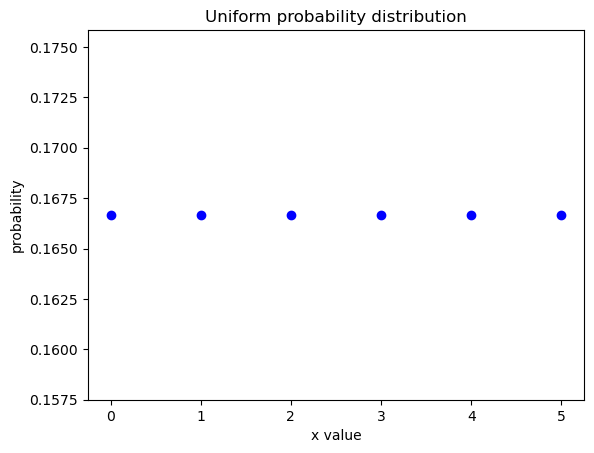

In [21]:
distribution = np.array([3,3,3,3,3,3])
plt.plot(distribution / np.sum(distribution), "ob")
plt.title("Uniform probability distribution")
plt.xlabel("x value")
plt.ylabel("probability")
plt.show()

### Binomial distribution

Bernoulli distribution arises in cases where there is binary outcome and the probability of outcome = 1 is given by parameter p. The probability of outcome = 0 is then (1 - p). When N experiments are conducted, the results follow the binomial distribution with parameters n and p.

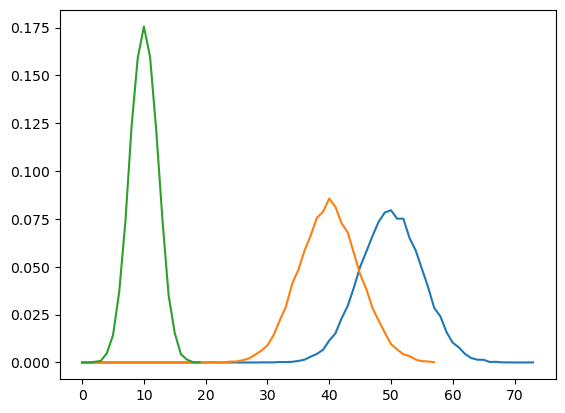

In [22]:
m = 20000

samples1 = np.random.binomial(100, 0.5, m)
distribution1 = np.bincount(samples1)
samples2 = np.random.binomial(100, 0.4, m)
distribution2 = np.bincount(samples2)
samples3 = np.random.binomial(20, 0.5, m)
distribution3 = np.bincount(samples3)

plt.plot(distribution1 / np.sum(distribution1))
plt.plot(distribution2 / np.sum(distribution2))
plt.plot(distribution3 / np.sum(distribution3))

plt.show()

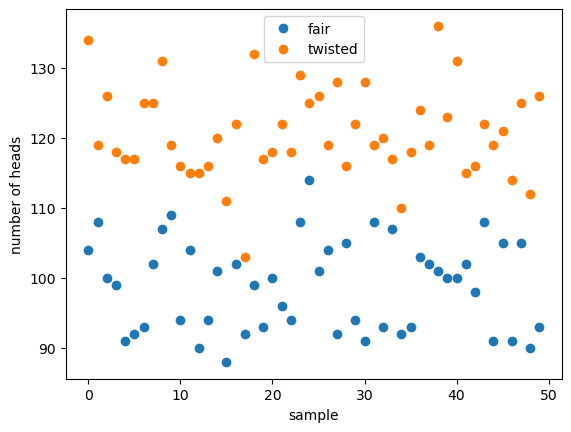

In [23]:
n = 200 # number of coins flipped in one experiment
n_experiments = 50
fair_samples = np.random.binomial(n, 0.5, n_experiments) # gives # of heads in sample
twisted_samples = np.random.binomial(n, 0.6, n_experiments)

plt.plot(fair_samples, "o", label="fair")
plt.plot(twisted_samples, "o", label="twisted")
plt.legend()
plt.xlabel("sample")
plt.ylabel("number of heads")
plt.show()

### Normal distribution

Let's do an experiment with a dice. Assume the dice is fair (each outcome 1..6 is equally probable) so we use uniform distribution (random.randrange() gives random numbers with a uniform distribution of values in a range). 

Let's throw 10 dices and record their sum and do this 50000 times. In the below code the sums are collected into Python list sums. If we now plot the sums histogram, the shape is familiar - the sums are distributed following normal, or Gaussian, distribution. This result is a consequence of central limit theorem (see https://en.wikipedia.org/wiki/Central_limit_theorem).

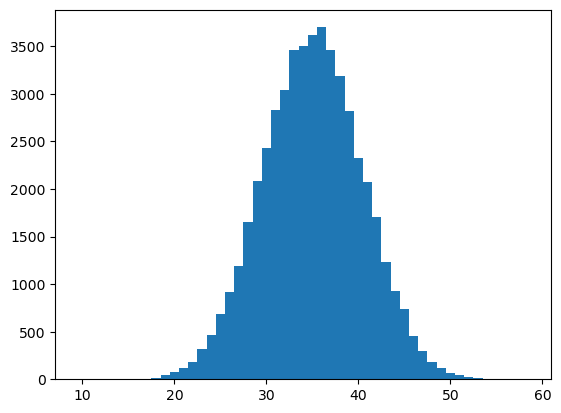

In [24]:
import random

sums = []
for rounds in range(50000):
    sum = 0
    for dices in range(10):
        sum += random.randrange(1,7)
    sums.append(sum)
    
plt.hist(sums, bins=range(10,60), align='left')
plt.show()

We could again sample from normal distribution and see if the sampled data is in line with our experiment. This time, however, we plot the Probability Density Function (PDF) directly by using scipy.stats module norm.pdf function. Parameters are calculated (see any statistics textbook or wikipedia), and:

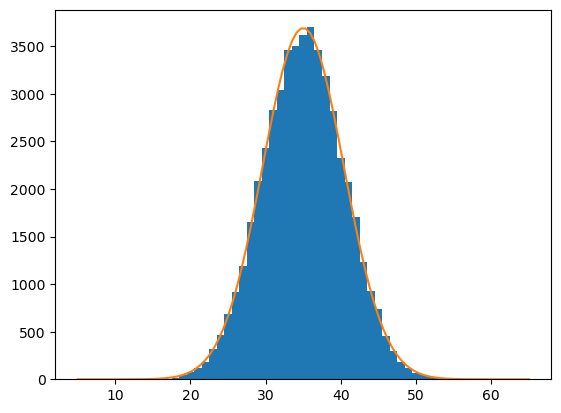

In [25]:
x = np.linspace(5,65,100)
plt.hist(sums, bins=range(10,60), align='left')

import math
from scipy.stats import norm
plt.plot(x, 50000*norm.pdf(x, loc=35, scale=math.sqrt(29.17)))
plt.show()

Some normal distributions with different parameters (mean and standard deviation):

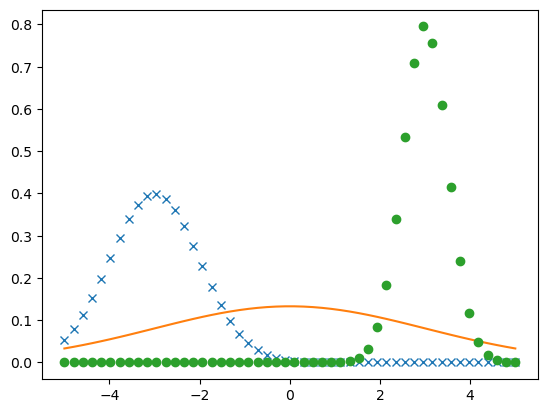

In [26]:
x = np.linspace(-5,5)

plt.plot(x, norm.pdf(x, -3,1), 'x')
plt.plot(x, norm.pdf(x, 0,3), '-')
plt.plot(x, norm.pdf(x, 3,0.5), 'o')

plt.show()

#### Cumulative distribution function (CDF)

The corresponding cumulative distributions for normal distributions in the previous example are plotted next. In a cumulative distribution the probabilities are summed up to the point plotted, ie. they give the probability of a random variable having a value lower than the x value. For example the blue plot is at almost 1 at point 0, meaning it is almost certain that a value from normal distribution centered at -3 with standard deviation 1 gives values < 0. Orange distribution, centered at 0, has probability 0.5 of giving negative values (which is self-evident, because it is centered at 0 and normal distributions are symmetric).

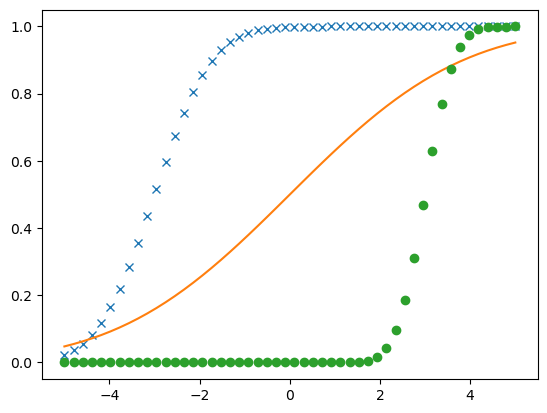

In [27]:
x = np.linspace(-5,5)

plt.plot(x, norm.cdf(x, -3,1), 'x')
plt.plot(x, norm.cdf(x, 0,3), '-')
plt.plot(x, norm.cdf(x, 3,0.5), 'o')

plt.show()

### Multidimensional distributions and illustrations

Often a single observation has more than one features, for example a human height and weight might be observed. If the features follow normal distribution then mean and standard deviation are enough to describe them. If these statistics, and the dependencies between the features (co-variances) are known, then a contour map could be plotted to illustrate the relationship. In a countour map lines with equal probabilities are plotted to give an idea about the nature of the relationship.

In [28]:
# create a grid - values from -6 to 12 with 0.025 intervals both in x and y direction
delta = 0.025
xs1 = np.arange(-6.0, 12.0, delta)
xs2 = np.arange(-6.0, 12.0, delta)
xx1, xx2 = np.meshgrid(xs1,xs2)
pos = np.dstack((xx1, xx2)) # a two-dimensional (x and y) position

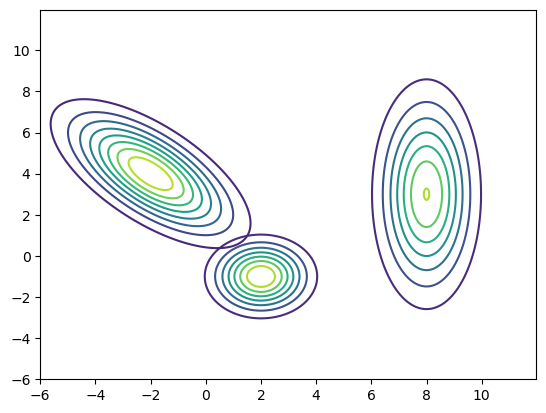

In [29]:
mu1 = [2,-1] # means

# s1 is a co-variance matrix; here variance for both features is 1 and 
# there is no co-variance - the features are independent, ie. knowing
# value of one the features reveals no information about the other

s1 = [[1,0],[0,1]] 
rv = multivariate_normal(mu1, s1)
Z = rv.pdf(pos)
plt.contour(xx1, xx2, Z, 8)

# In the next example co-variance matrix s2 has non-zero
# values (here -2.0) in non-diagonal positions. It means
# that the features co-vary, ie. depend on each other to some degree.
# Graphically co-variance between features is illustrated by the tilted ellipse.

mu2 = [-2,4]
s2 = [[3,-2],[-2,3]] 
rv = multivariate_normal(mu2, s2)
Z = rv.pdf(pos)
plt.contour(xx1, xx2, Z, 8)

# In the next example there is no co-variance, but
# variance in y direction greater than in x direction.
# This is illustrated by the squeezed shape of the contour
# digram ellipsis.

mu3 = [8,3]
s3 = [[1,0],[0,8]] 
rv = multivariate_normal(mu3, s3)
Z = rv.pdf(pos)
plt.contour(xx1, xx2, Z, 8)

plt.show()

## Comparing probability distributions

How could we know if two distributions are close to each other? One possibility is to use Kullback-Leibler (KL) divergence. Its root are in information theory and we won't go into details here. See https://en.wikipedia.org/wiki/Kullback%E2%80%93Leibler_divergence for more if interested.

KL divergence is not a metric, for example KL(A||B) is not equal to KL(B||A).

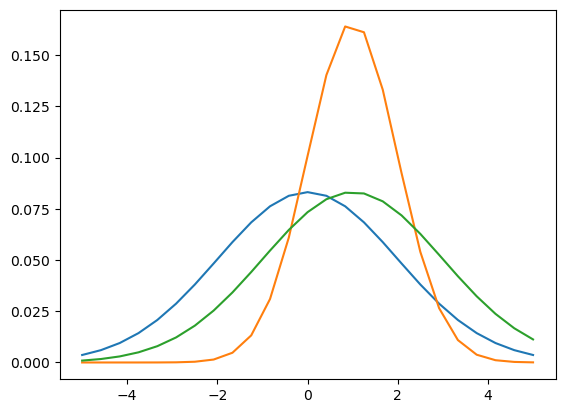

0.0
1.1907284646961562
0.4432103296320933
0.3182243503503581


In [30]:
x = np.linspace(-5,5,25)
distA = norm.pdf(x, loc=0, scale=2.0)*(x[1]-x[0])
distB = norm.pdf(x, loc=1, scale=1.0)*(x[1]-x[0])
distC = norm.pdf(x, loc=1, scale=2.0)*(x[1]-x[0])

plt.plot(x, distA)
plt.plot(x, distB)
plt.plot(x, distC)
plt.show()

# need to sum up the results vector for KL div, rel_entr() is KL div
print(np.sum(scipy.special.rel_entr(distA, distA))) 
print(np.sum(scipy.special.rel_entr(distA, distB)))
print(np.sum(scipy.special.rel_entr(distB, distA)))
print(np.sum(scipy.special.rel_entr(distB, distC)))

## Numpy and images

An image (in jpg, png etc format) can be read in with matplotlib imread function, for example. A color image will have shape (height, width, 3) if the image is read in RGB format (third dimension, or depth, contains pixel values for each of the three colors). Sometimes an image is stored in a format that contains alpha (luminocity) channel in addition to R, G and B. In this case the depth is 4.

Image pixel values represent the brightness values, typically 0-255 (stored in one byte). For processing images, the values are usually converted to 0.0 .. 1.0 range (just divide by 255).

rawimage shape (600, 893, 3)
(100,300): [150 198 220]
rawimage dtype uint8
0 255 109.68701816598234


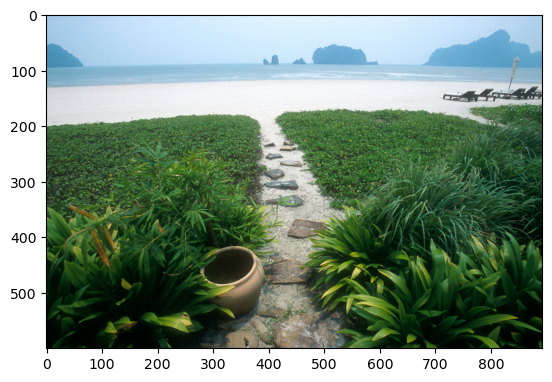

image shape (600, 893, 3)
(100,300): [0.58823529 0.77647059 0.8627451 ]
Image dtype float64
0.0 1.0 0.43014516927836205


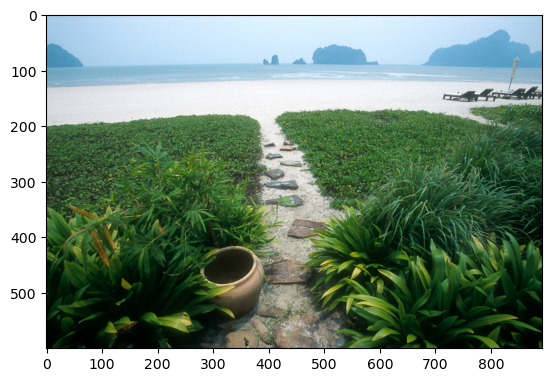

In [31]:
# Make sure kuva.jpg is in the same directory as this notebook
rawimage = plt.imread("kuva.jpg")

print("rawimage shape", rawimage.shape)
print("(100,300):",rawimage[100,300,:]) # select a slice at position 100, 300: gives the channel values (R,G,B)
print("rawimage dtype", rawimage.dtype)
print(np.min(rawimage), np.max(rawimage), np.mean(rawimage))
plt.imshow(rawimage)
plt.show()

image = rawimage / 255 # map to 0..1 range and convert to float

print("image shape", image.shape)
print("(100,300):",image[100,300,:])
print("Image dtype", image.dtype)
print(np.min(image), np.max(image), np.mean(image))
plt.imshow(image)
plt.show()

Let's create a copy of the image array and change it.

In [1]:
tmpimage = image.copy()
tmpimage[150:180, 300:330, :] = (1,0,0)
plt.imshow(tmpimage)
plt.show()

NameError: name 'image' is not defined

Display R, G and B channels separately. (cmap argument specifies the colormap for imshow(). 
Default map is for showing multichannel images and has settings to improve appearance.)

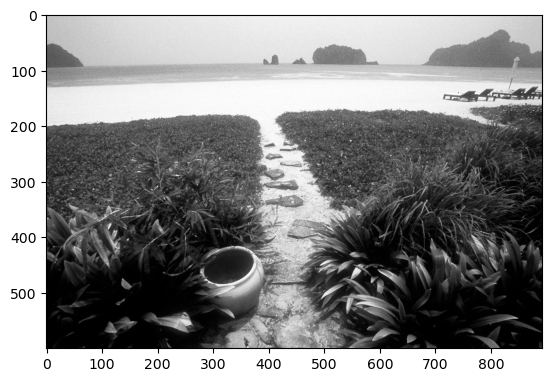

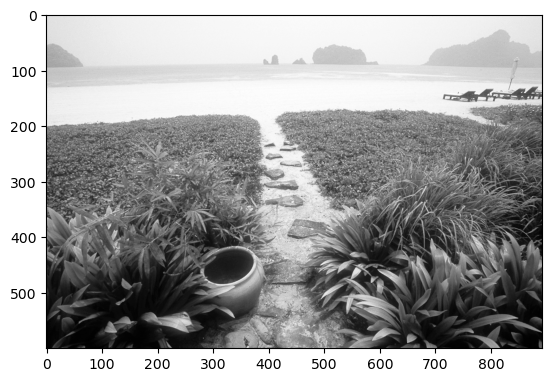

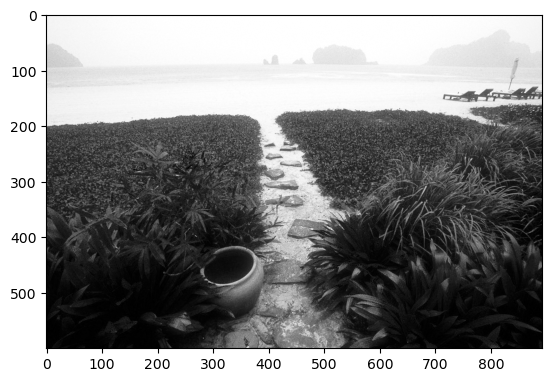

In [33]:
for ch in range(3):
    plt.imshow(1-image[:,:,ch],cmap='Greys') # 1 - pixel value -> positive image instead of negative
    plt.show()

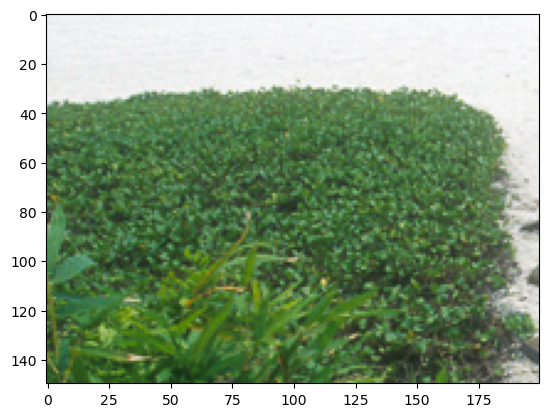

In [34]:
# Let's take a look at part of the image only.
plt.imshow(image[150:300, 200:400, :])
plt.show()

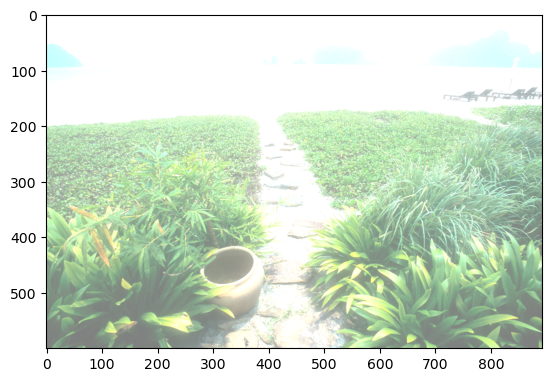

In [35]:
# Let's brighten the image
brightimage = np.minimum(image + 0.5, 1.0) # minimum <> min: min acts on a range, minimum on parameter values
plt.imshow(brightimage)
plt.show()

0.0 1.0 0.49360653741153054


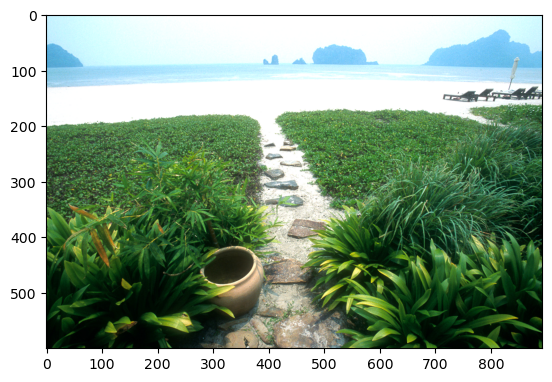

0.0 1.0 0.5419749643194341


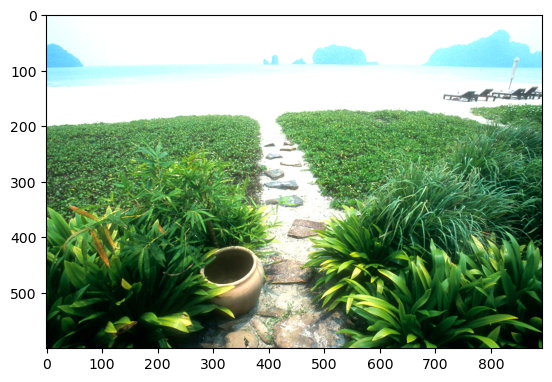

0.0 1.0 0.5876841699492785


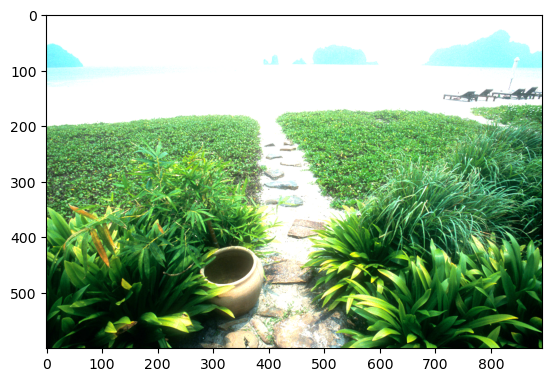

0.0 1.0 0.6334767876922174


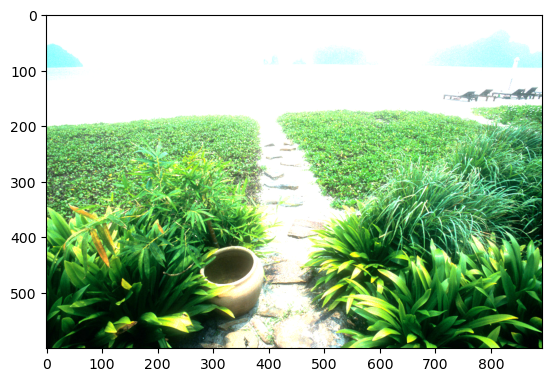

0.0 1.0 0.6780862583773573


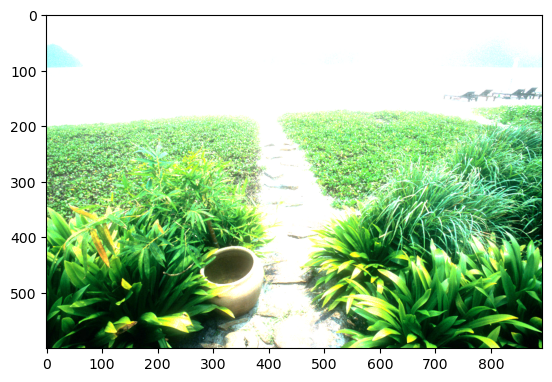

In [36]:
for i in range(5):
    image = np.minimum(image*1.2,1.0)
    print(np.min(image), np.max(image), np.mean(image))
    plt.imshow(image)
    plt.show()